In [4]:
!python -m venv $HOME/nb-venvs/esgf-stac --system-site-packages

In [5]:
!. $HOME/nb-venvs/esgf-stac/bin/activate

In [6]:
!pip install ipykernel

Defaulting to user installation because normal site-packages is not writeable


In [8]:
!$HOME/nb-venvs/esgf-stac/bin/pip install fsspec pystac_client esgvoc aiohttp


[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python -m pip install --upgrade pip


In [9]:
!$HOME/nb-venvs/esgf-stac/bin/python -m ipykernel install --user --name=esgf-stac-env

Installed kernelspec esgf-stac-env in /home/users/pjkersha/.local/share/jupyter/kernels/esgf-stac-env


In [1]:
import pystac_client
import xarray as xr
import fsspec
import esgvoc.api as ev

### Search using ESGF East Index 

In [2]:
stac_endpoint = "https://api.stac.esgf.ceda.ac.uk"

In [3]:
clnt = pystac_client.Client.open(stac_endpoint)

### Check top-levels collections for CMIP6 present

In [4]:
collection_name = None

for coll in clnt.get_collections():
    print(f"{coll.id}: {coll.description}")
    if coll.id.upper() == "CMIP6":
        collection_name = coll.id

print(f"Using collection: {collection_name}") 

CMIP6: CMIP6
obs4MIPs: obs4MIPs
Using collection: CMIP6


### Search based on ScenarioMIP which has been indexed with Virtualizarr references

In [5]:
print(f"Searching in collection: {collection_name}")
item_search = clnt.search(
    collections=["CMIP6"],
    query=[
        "cmip6:activity_id=ScenarioMIP",
        "cmip6:variant_label=r1i1p1f1",
        "cmip6:frequency=day",
        "cmip6:variable_id=tas"
    ],
    max_items=200,
)
print(f"Number of items found: {item_search.matched()}")

Searching in collection: CMIP6
Number of items found: 17


In [6]:
items = list(item_search.items())

### Pick the first search hit, extract the Kerchunk reference and load in xarray

In [7]:
kc_file = items[0].assets['reference_file']
zarr_kwargs = kc_file.to_dict()['open_zarr_kwargs']

# Temporary fudge for discrepancy in file format - search index vs. file system
kc_file_uri = kc_file.href.replace("_", ".")

### Nb. using xarray version 2025.7.0. Later version has different inputs - kerchunk option not supported 

In [8]:
# Nb. open_dataset function signature has changed over different versions of xarray
# Below works for xarray 2025.7.0
ds = xr.open_dataset(
    kc_file_uri,
    engine="kerchunk",
    open_dataset_options={"chunks": {}},
)

/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/pyproj/__init__.py:96: UserWarning: Valid PROJ data directory not found. Either set the path using the environmental variable PROJ_DATA (PROJ 9.1+) | PROJ_LIB (PROJ<9.1) or with `pyproj.datadir.set_data_dir`.
  warnings.warn(str(err))
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'gini' loading failed:
Valid PROJ data directory not found. Either set the path using the environmental variable PROJ_DATA (PROJ 9.1+) | PROJ_LIB (PRO

In [9]:
ds

<xarray.Dataset> Size: 7GB
Dimensions:    (lat: 180, bnds: 2, lon: 288, time: 31390)
Coordinates:
  * bnds       (bnds) float64 16B 1.0 2.0
  * lat        (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon        (lon) float64 2kB 0.625 1.875 3.125 4.375 ... 356.9 358.1 359.4
  * time       (time) object 251kB 2015-01-01 12:00:00 ... 2100-12-31 12:00:00
    height     float64 8B ...
Data variables:
    lat_bnds   (lat, bnds) float64 3kB ...
    lon_bnds   (lon, bnds) float64 5kB ...
    tas        (time, lat, lon) float32 7GB ...
    time_bnds  (time, bnds) object 502kB ...
Attributes: (12/46)
    external_variables:     areacella
    history:                File was processed by fremetar (GFDL analog of CM...
    table_id:               day
    activity_id:            ScenarioMIP
    branch_method:          standard
    branch_time_in_child:   60225.0
    ...                     ...
    title:                  NOAA GFDL GFDL-ESM4 model output prepared for CMI...
    tracking_id:            hdl:21.14100/67dc9ebf-4e0f-46c8-b27d-ef5356922cc3
    variable_id:            tas
    variant_info:           N/A
    references:             see further_info_url attribute
    variant_label:          r1i1p1f1

### Plot first time step

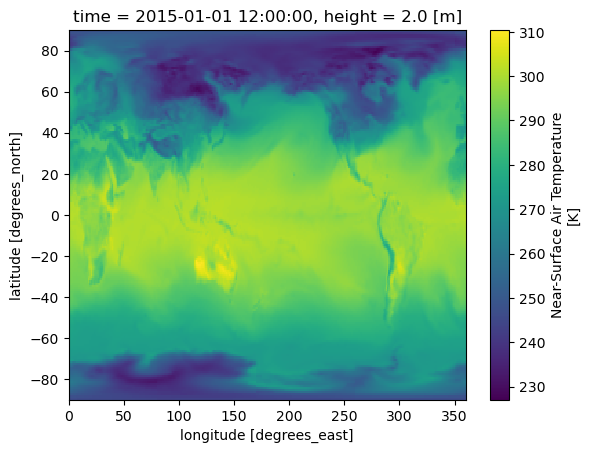

In [10]:
ds.sel(time='2015-01').isel(time=0).tas.plot()

In [11]:
xr.show_versions()


INSTALLED VERSIONS
------------------
commit: None
python: 3.12.11 | packaged by conda-forge | (main, Jun  4 2025, 14:45:31) [GCC 13.3.0]
python-bits: 64
OS: Linux
OS-release: 5.14.0-611.27.1.el9_7.x86_64
machine: x86_64
processor: x86_64
byteorder: little
LC_ALL: None
LANG: None
LOCALE: ('C', 'UTF-8')
libhdf5: 1.14.3
libnetcdf: 4.9.2

xarray: 2025.7.0
pandas: 2.3.0
numpy: 2.2.6
scipy: 1.15.2
netCDF4: 1.7.2
pydap: 3.5.5
h5netcdf: 1.6.3
h5py: 3.13.0
zarr: 3.0.10
cftime: 1.6.4
nc_time_axis: 1.4.1
iris: 3.12.2
bottleneck: None
dask: 2025.5.1
distributed: 2025.5.1
matplotlib: 3.10.3
cartopy: None
seaborn: 0.13.2
numbagg: None
fsspec: 2025.5.1
cupy: None
pint: 0.24.4
sparse: 0.17.0
flox: 0.10.4
numpy_groupies: 0.11.3
setuptools: 80.9.0
pip: 25.0.1
conda: None
pytest: 8.4.1
mypy: None
IPython: 9.4.0
sphinx: 8.2.3
